**Cosa fare**

1. misure lunghezza
2. prendere misure periodo a vaie lunghezze
3. confrontare periodo atteso e ottenuto

plottare in grafico lab per vedere legger di potenza , y=T e x =l

### Get data

In [170]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.optimize import curve_fit

In [171]:
# Masse in grammi

m_spring = 8.642
m_mass = [50.025, 20.009, 10.008, 5.002]
m_sostegno = 7.836

# in grams

In [172]:
# for formula of period  
m_period_kg = [(x+m_sostegno+m_spring/3)/1000 for x in m_mass]

# in kg

cosa fare: 

1-- stimare k 

prendo tanti periodi per stimare k  
poi mg=kl  
k l'ho stimata  

mg = kl  
(m_molla + m_obj)g = kl  

misuro l, trovo g  

ripetere per tutte le masse  



In [173]:
# Prendine di più, usa combinazioni di masse, tipo m_1+m_2  
# e meglio fare più di 10 oscillazioni, tipo 20, visto che non sono molto precise così

periods = np.array([
[9.76, 9.80, 9.75, 9.84, 9.84, 9.77, 9.75, 9.77, 9.77, 9.74],  # big
[6.96, 7.04, 7.02, 6.97, 6.93, 6.94, 6.92, 7.03, 6.97, 6.95],  
[5.77, 5.70, 5.69, 5.69, 5.74, 5.65, 5.75, 5.70, 5.63, 5.80],
[5.06, 4.99, 5.05, 5.00, 4.99, 4.93, 5.07, 4.93, 4.93, 4.96]
])

mg = k l  


In [174]:
l = np.array([15.9, # m_1
              18.0, # m_2
              21.3, # m_3
              34.1, # m_4
              19.8, # m_1+m_2
              24.5, # m_1+m_3
              35.9]) # m_1+m_4

l_rest = 14.1  # verticale + sostegno

# in cm  

### Incertezze, elabora dati

In [175]:
sigma_l= np.full(l.shape, 0.5)  
sigma_m = 0.001

# sigma_l va AUMENTATA DI MOLTO, NON PRENDERE LA RISOLUZIONE DEL METRO  
 

# Pay attention to the units: if l is in cm, sigma_l too

In [176]:
T = np.mean(periods, axis=1)/10
sigma_T = np.std(periods/10, ddof=1, axis=1)

### Stampa tabelle

In [177]:
for i in range(len(periods)):
    print(f'm: {m_period_kg[i]:.2f}, T = {T[i]:.3f} + {sigma_T[i]:.3f}')

m: 0.06, T = 0.978 + 0.004
m: 0.03, T = 0.697 + 0.004
m: 0.02, T = 0.571 + 0.005
m: 0.02, T = 0.499 + 0.005


In [178]:
# Tabella piccola

for i in range(len(l)):
    print(f'{l[i]:.2f}')

15.90
18.00
21.30
34.10
19.80
24.50
35.90


In [179]:
for i in range(len(periods)):
    formatted = ' & '.join(f'{value:.2f}' for value in periods[i])
    print(f'{l[i]:.2f} & {formatted} \\\\')

15.90 & 9.76 & 9.80 & 9.75 & 9.84 & 9.84 & 9.77 & 9.75 & 9.77 & 9.77 & 9.74 \\
18.00 & 6.96 & 7.04 & 7.02 & 6.97 & 6.93 & 6.94 & 6.92 & 7.03 & 6.97 & 6.95 \\
21.30 & 5.77 & 5.70 & 5.69 & 5.69 & 5.74 & 5.65 & 5.75 & 5.70 & 5.63 & 5.80 \\
34.10 & 5.06 & 4.99 & 5.05 & 5.00 & 4.99 & 4.93 & 5.07 & 4.93 & 4.93 & 4.96 \\


## Get k

### Fit

In [180]:
def model(m, k):
    """Modello per il periodo del pendolo."""
    return 2.0 * np.pi * np.sqrt(m/k)

In [181]:
x = m_period_kg  # [kg]
y = T         # [s]
sigma_x = sigma_m
sigma_y = sigma_T 
model = model

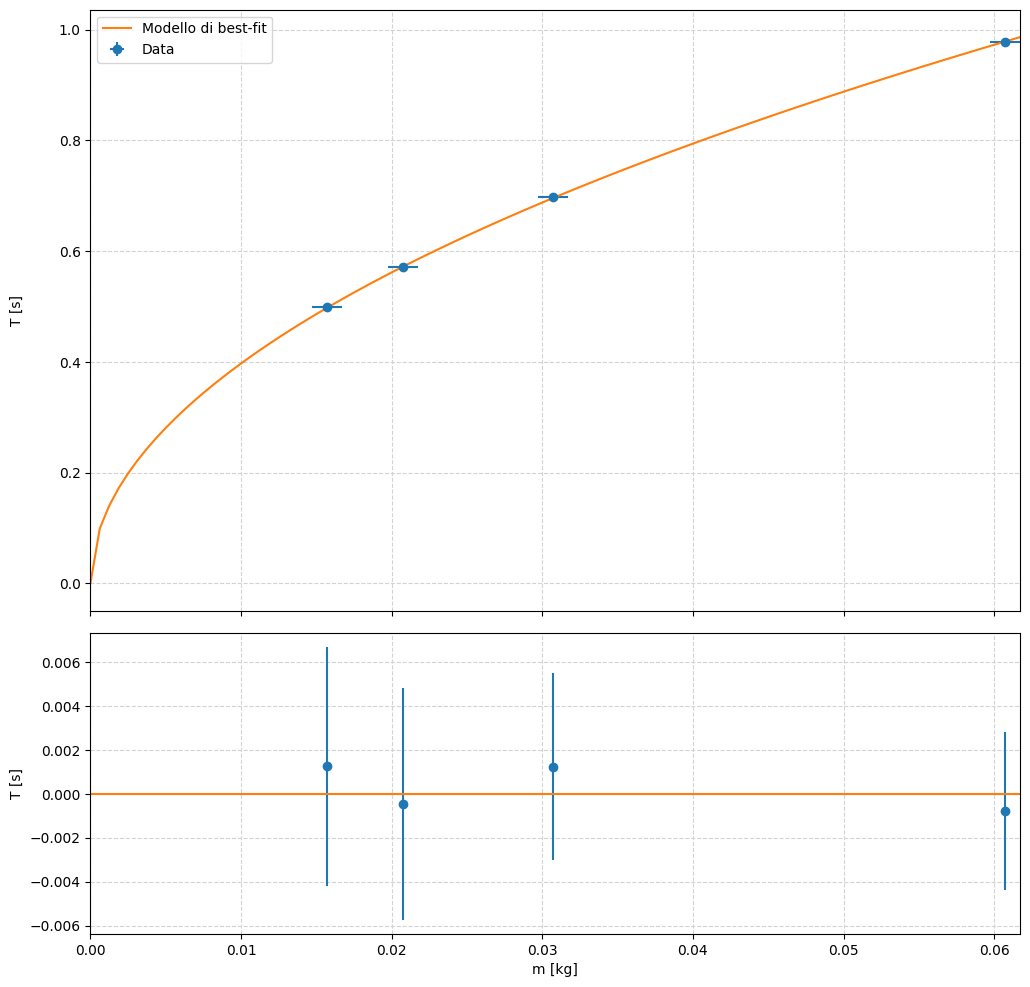

In [182]:
# Fit
popt, pcov = curve_fit(model, x, y, sigma=sigma_y)
res = y - model(x, *popt)

# Create the main figure
fig = plt.figure(figsize=(12, 12))
ax1, ax2 = fig.subplots(2, 1, sharex=True, gridspec_kw=dict(height_ratios=[2, 1], hspace=0.05))
x_lim = max(x)+0.001
xgrid = np.linspace(0.0, x_lim, 100)

# Main plot: the scatter plot of x vs. y, on the top panel.
ax1.errorbar(x, y, xerr=sigma_x, yerr=sigma_y+0.001, fmt='o', label='Data')
ax1.plot(xgrid, model(xgrid, *popt), label='Modello di best-fit')

# And now the residual plot, on the bottom panel.
ax2.errorbar(x, res, sigma_y, fmt='o')
ax2.plot(xgrid, np.full(xgrid.shape, 0.0)) # horizontal line at y=0

# STYLING  

ax1.set_ylabel('T [s]')
ax1.grid(color='lightgray', ls='dashed')
ax1.legend()

ax2.set_ylabel('T [s]')
ax2.set_xlabel('m [kg]')
ax2.grid(color='lightgray', ls='dashed')

plt.xlim(0.0, x_lim)
fig.align_ylabels((ax1, ax2))

plt.show()

In [183]:
# Print results  

print(f'Parameters: {popt}')
print(f'Errors: {np.sqrt(np.diag(pcov))}')

k = popt

Parameters: [2.5036069]
Errors: [0.00363825]


### Check

In [184]:
chisq = np.sum((res / sigma_y)**2)
dof = len(y) - len(popt)
chi2_red = chisq / dof  # must give 1  

print(f'Chi: {chisq}')
print(f'Dof: {dof}')
print(f'Chi reduced: {chi2_red}')

Chi: 0.19063357432222966
Dof: 3
Chi reduced: 0.06354452477407656


In [185]:
from scipy.stats import chi2

p_value = chi2.sf(chisq, dof)
print(f"P-value: {p_value}")

P-value: 0.9790870058301548


## Find g

mg = kl  

misuro l, trovo g  

ripetere per tutte le masse  



### Fit

In [186]:
def line(x, m):
    return m * x

In [187]:
mass_gram = [m_mass[3],
        m_mass[2],
        m_mass[1],
        m_mass[0],
        m_mass[3]+m_mass[2],
        m_mass[3]+m_mass[1],
        m_mass[3]+m_mass[0]
        ]   # in grammi 

displace_meter = [(x-l_rest)/100 for x in l] # in metri

In [188]:
for i in range(len(mass_gram)):
    print(f'{mass_gram[i]:.2f} & {displace_meter[i]:.3f}\\\\')

5.00 & 0.018\\
10.01 & 0.039\\
20.01 & 0.072\\
50.02 & 0.200\\
15.01 & 0.057\\
25.01 & 0.104\\
55.03 & 0.218\\


In [189]:
x_1 = [(a/1000)/(b/100) for a,b in zip(mass_gram, displace_meter)]

In [190]:
x_1

[np.float64(27.788888888888877),
 np.float64(25.661538461538456),
 np.float64(27.790277777777774),
 np.float64(25.0125),
 np.float64(26.333333333333325),
 np.float64(24.04903846153846),
 np.float64(25.241743119266058)]

In [191]:
model=line 

mass_gram = np.asarray(mass_gram, dtype=float)
displace_meter = np.asarray(displace_meter, dtype=float)

x = mass_gram / 1000
y = displace_meter * k

sigma_x = sigma_m / 1000
sigma_y = sigma_l / 100 * k * 2

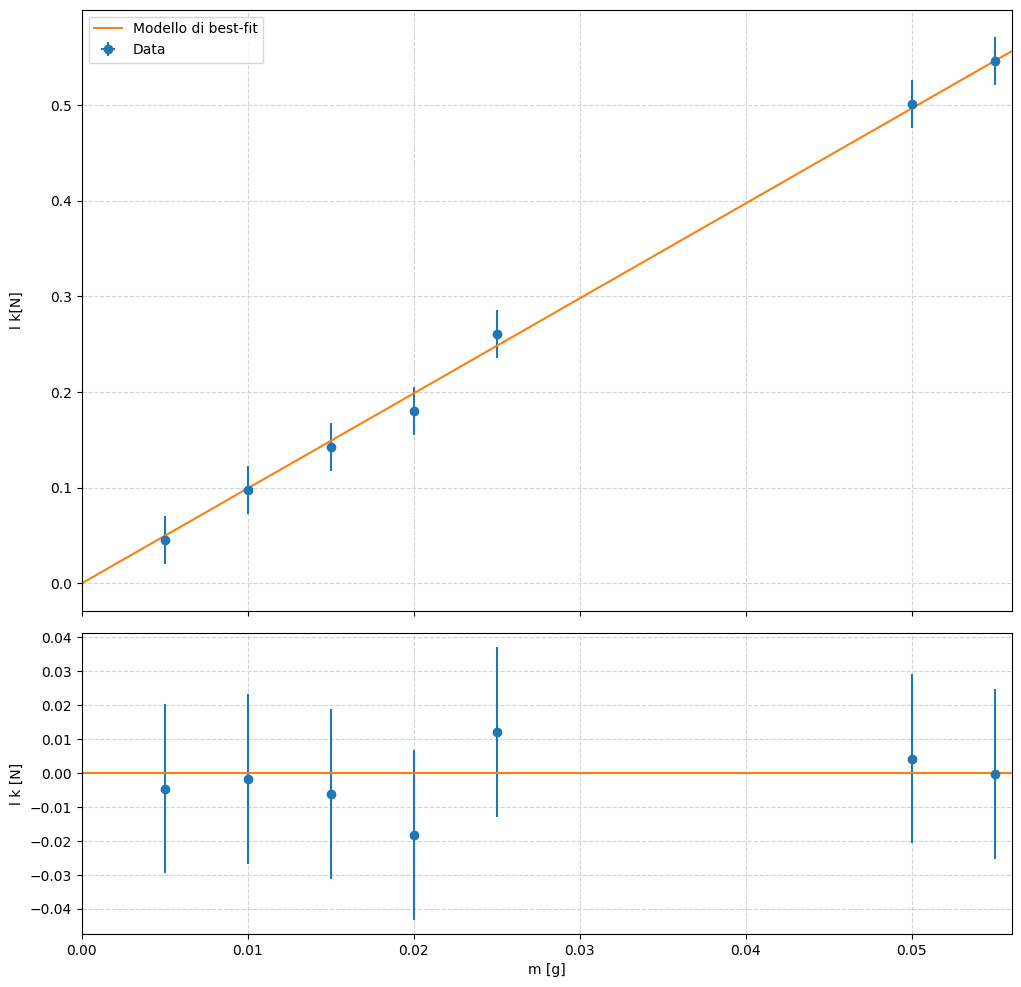

In [192]:
# Fit
popt2, pcov2 = curve_fit(model, x, y, sigma=sigma_y)
res = y - model(x, popt2)

# Create the main figure
fig = plt.figure(figsize=(12, 12))
ax1, ax2 = fig.subplots(2, 1, sharex=True, gridspec_kw=dict(height_ratios=[2, 1], hspace=0.05))
x_lim = max(x)+0.001
xgrid = np.linspace(0.0, x_lim, 100)

# Main plot: the scatter plot of x vs. y, on the top panel.
ax1.errorbar(x, y, xerr=sigma_x, yerr=sigma_y, fmt='o', label='Data')
ax1.plot(xgrid, model(xgrid, *popt2), label='Modello di best-fit')

# And now the residual plot, on the bottom panel.
ax2.errorbar(x, res, sigma_y, fmt='o')
ax2.plot(xgrid, np.full(xgrid.shape, 0.0)) # horizontal line at y=0

# STYLING  

ax1.set_ylabel('l k[N]')
ax1.grid(color='lightgray', ls='dashed')
ax1.legend()

ax2.set_ylabel('l k [N]')
ax2.set_xlabel('m [g]')
ax2.grid(color='lightgray', ls='dashed')

plt.xlim(0.0, x_lim)
fig.align_ylabels((ax1, ax2))

plt.show()

In [193]:
popt2

array([9.92422386])

### Check

In [194]:
chisq = np.sum((res / sigma_y)**2)
dof = len(y) - len(popt)
chi2_red = chisq / dof  # must give 1  

print(f'Chi: {chisq}')
print(f'Dof: {dof}')
print(f'Chi reduced: {chi2_red}')

p_value = chi2.sf(chisq, dof)
print(f"P-value: {p_value}")

Chi: 0.90053606264436
Dof: 6
Chi reduced: 0.15008934377406
P-value: 0.9891033581530954


In [195]:
pcov2

array([[0.01362076]])

### WIth ODR

In [196]:
def power_law_odr(pars, x): # pars A,n
    # Note the independent variable is the last argument.
    return pars[0] * x

In [197]:
from scipy import odr

model = odr.Model(power_law_odr)
data = odr.RealData(x, y, sx=sigma_x, sy=sigma_y)
alg = odr.ODR(data, model, beta0=(1.0, 1.0))
out = alg.run()

A_fit = out.beta
sigma_A = np.sqrt(out.cov_beta.diagonal())
chisq_odr = out.sum_square

In [198]:
sigma_A

array([0.30124911, 0.        ])

In [199]:
chisq_odr

0.9005359211425917